In [ ]:
# 1. Import the Google Drive mounting utility
from google.colab import drive

# 2. Connect Google Drive to this Colab session
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Set the project folder and dataset path
import os

PROJECT_DIR = '/content/drive/MyDrive/TED_Talk_Recommendation'
DATA_PATH = os.path.join(PROJECT_DIR, 'ted_talks_en.csv')

print("Dataset found:", os.path.exists(DATA_PATH))

Dataset found: True


In [ ]:
# Import libraries and load the TED Talks dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast
import re
from collections import Counter

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Number of rows: 4005
Number of columns: 19


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


In [ ]:
# Inspect the dataset structure and column data types
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Column names:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   talk_id         4005 non-null   int64  
 1   title           4005 non-null   object 
 2   speaker_1       4005 non-null   object 
 3   all_speakers    4001 non-null   object 
 4   occupations     3483 non-null   object 
 5   about_speakers  3502 non-null   object 
 6   views           4005 non-null   int64  
 7   recorded_date   4004 non-null   object 
 8   published_date  4005 non-null   object 
 9   event           4005 non-null   object 
 10  native_lang     4005 non-null   object 
 11  available_l

In [ ]:
# Analyse missing values in the dataset
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

display(missing_summary[missing_summary['Missing Count'] > 0]
        .sort_values('Missing Count', ascending=False))

,Missing Count,Missing Percentage
comments,655,16.35
occupations,522,13.03
about_speakers,503,12.56
all_speakers,4,0.10
recorded_date,1,0.02


In [ ]:
# Check for duplicate rows and duplicate talk identifiers
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate talk IDs:", df['talk_id'].duplicated().sum())

Exact duplicate rows: 0
Duplicate talk IDs: 0


Average topics per talk: 7.915106117353308
Minimum topics per talk: 1
Maximum topics per talk: 33


,Topic,Number of Talks
0,science,993
1,technology,979
2,culture,680
3,TEDx,581
4,global issues,574
5,TED-Ed,563
6,society,557
7,design,518
8,social change,512
9,animation,487


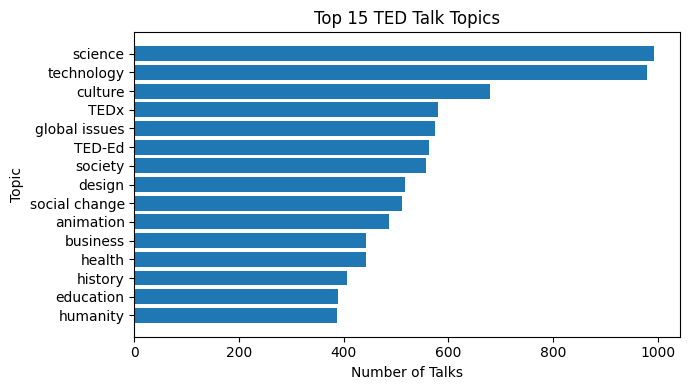

In [ ]:
# Analyse topic frequencies and visualise the top 15 topics

def parse_list(value):
    if pd.isna(value):
        return []
    try:
        result = ast.literal_eval(value) if isinstance(value, str) else value
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError):
        return []

topic_lists = df['topics'].apply(parse_list)

# Count the number of topics associated with each talk
df['topic_count'] = topic_lists.apply(len)

print("Average topics per talk:", df['topic_count'].mean())
print("Minimum topics per talk:", df['topic_count'].min())
print("Maximum topics per talk:", df['topic_count'].max())

# Count how often each topic appears
topic_counter = Counter(
    str(topic).strip()
    for topics in topic_lists
    for topic in topics
    if str(topic).strip()
)

top_topics = pd.DataFrame(
    topic_counter.most_common(15),
    columns=['Topic', 'Number of Talks']
)

display(top_topics)

# Visualise the 15 most common topics
plt.figure(figsize=(7, 4))
plt.barh(top_topics['Topic'][::-1],
         top_topics['Number of Talks'][::-1])

plt.xlabel('Number of Talks')
plt.ylabel('Topic')
plt.title('Top 15 TED Talk Topics')
plt.tight_layout()
plt.show()

Unique primary speakers: 3274
Speakers with multiple talks: 424


,Number of Talks
Speaker,
Alex Gendler,34
Iseult Gillespie,19
Emma Bryce,12
Daniel Finkel,11
Alex Rosenthal,10
Hans Rosling,10
Greg Gage,9
Juan Enriquez,9
Chris Anderson,8


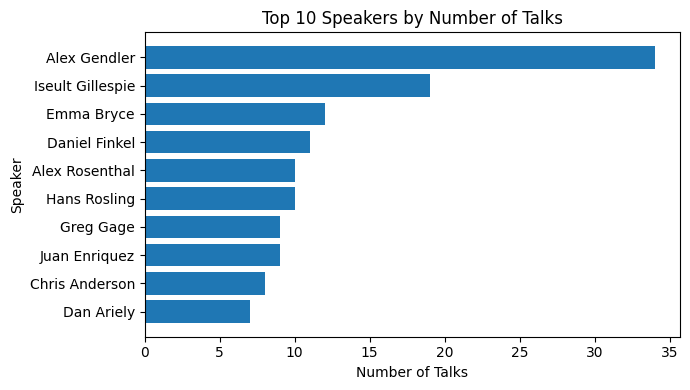

In [ ]:
# Analyse speaker frequency and visualise the top 10 speakers

print("Unique primary speakers:", df['speaker_1'].nunique())

speaker_counts = df['speaker_1'].value_counts()
repeat_speakers = speaker_counts[speaker_counts > 1]

print("Speakers with multiple talks:", len(repeat_speakers))
display(repeat_speakers.head(20).rename_axis('Speaker')
        .to_frame('Number of Talks'))

top_speakers = speaker_counts.head(10)

plt.figure(figsize=(7, 4))
plt.barh(top_speakers.index[::-1], top_speakers.values[::-1])

plt.xlabel('Number of Talks')
plt.ylabel('Speaker')
plt.title('Top 10 Speakers by Number of Talks')
plt.tight_layout()
plt.show()

In [ ]:
# Analyse all speaker names, including co-speakers

all_speaker_names = []

for value in df['all_speakers'].dropna():
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else value
    except (ValueError, SyntaxError):
        continue

    if isinstance(parsed, dict):
        all_speaker_names.extend(
            str(name).strip() for name in parsed.values()
            if str(name).strip()
        )
    elif isinstance(parsed, list):
        all_speaker_names.extend(
            str(name).strip() for name in parsed
            if str(name).strip()
        )

print("Unique names in all_speakers:", len(set(all_speaker_names)))

Unique names in all_speakers: 3349


In [ ]:
# Analyse word counts and text quality across TED Talk text columns

text_columns = ['title', 'description', 'transcript', 'about_speakers']

for col in text_columns:
    text_data = df[col].fillna('').astype(str).str.strip()
    word_counts = text_data.str.split().str.len()

    print(f"\n--- {col.upper()} ---")
    print("Empty entries:", (text_data == '').sum())
    print("Average word count:", round(word_counts.mean(), 2))
    print("Minimum word count:", word_counts.min())
    print("Maximum word count:", word_counts.max())
    print("Entries with 5 or fewer words:", (word_counts <= 5).sum())
    print("Entries with more than 5000 words:", (word_counts > 5000).sum())


--- TITLE ---
Empty entries: 0
Average word count: 6.74
Minimum word count: 1
Maximum word count: 17
Entries with 5 or fewer words: 1345
Entries with more than 5000 words: 0

--- DESCRIPTION ---
Empty entries: 0
Average word count: 58.2
Minimum word count: 9
Maximum word count: 143
Entries with 5 or fewer words: 0
Entries with more than 5000 words: 0

--- TRANSCRIPT ---
Empty entries: 0
Average word count: 1796.85
Minimum word count: 2
Maximum word count: 11121
Entries with 5 or fewer words: 5
Entries with more than 5000 words: 22

--- ABOUT_SPEAKERS ---
Empty entries: 503
Average word count: 22.4
Minimum word count: 0
Maximum word count: 238
Entries with 5 or fewer words: 503
Entries with more than 5000 words: 0


In [ ]:
# Check whether TED Talk transcripts contain sufficient text

transcript_words = df['transcript'].fillna('').astype(str).str.split().str.len()

print("Empty transcripts:", (transcript_words == 0).sum())
print("Transcripts under 50 words:", (transcript_words < 50).sum())
print("Transcripts over 10000 words:", (transcript_words > 10000).sum())

display(
    df.loc[transcript_words < 50,
           ['title', 'speaker_1', 'transcript']].head(10)
)

Empty transcripts: 0
Transcripts under 50 words: 10
Transcripts over 10000 words: 3


,title,speaker_1,transcript
145,My magic moves,Kenichi Ebina,(Applause) (Music) (Applause)
303,Playing invisible turntables,James Burchfield,"Let's just get started here. Okay, just a mome..."
573,An all-star set,Herbie Hancock,(Music) (Applause) (Music) (Music) (Applause) ...
904,"On violin and cello, ""Passacaglia""",Robert Gupta,(Music) (Applause) (Music) (Applause)
1198,Dancing with light,Quixotic Fusion,(Music) (Applause) (Music) (Applause) (Music) ...
1393,"Dance, tiny robots!",Bruno Maisonnier,(Mechanical noises) (Music) (Applause)
1825,"A dance in a hurricane of paper, wind and light",Aakash Odedra,(Music) (Applause)
1948,An 11-year-old prodigy performs old-school jazz,Joey Alexander,(Music) (Music) (Applause) (Applause)
2029,A musical escape into a world of light and color,Kaki King,(Guitar music starts) (Music ends) (Applause) ...
2330,An electrifying acoustic guitar performance,Rodrigo y Gabriela,(Guitar music starts) (Cheers) (Cheers) (Music...


In [ ]:
# Analyse TED Talk views and identify the most-viewed talks

views = pd.to_numeric(df['views'], errors='coerce')

print("Mean views:", round(views.mean(), 2))
print("Median views:", views.median())
print("Minimum views:", views.min())
print("Maximum views:", views.max())
print("Missing views:", views.isna().sum())

top_viewed = df.loc[
    views.nlargest(10).index,
    ['title', 'speaker_1', 'views', 'url']
]

display(top_viewed)

Mean views: 2148005.57
Median views: 1375508.0
Minimum views: 0
Maximum views: 65051954
Missing views: 0


,title,speaker_1,views,url
4,Do schools kill creativity?,Sir Ken Robinson,65051954,https://www.ted.com/talks/sir_ken_robinson_do_...
1296,Your body language may shape who you are,Amy Cuddy,57074270,https://www.ted.com/talks/amy_cuddy_your_body_...
2062,This is what happens when you reply to spam email,James Veitch,56932551,https://www.ted.com/talks/james_veitch_this_is...
646,How great leaders inspire action,Simon Sinek,49730580,https://www.ted.com/talks/simon_sinek_how_grea...
796,The power of vulnerability,Brené Brown,47544833,https://www.ted.com/talks/brene_brown_the_powe...
1724,How to speak so that people want to listen,Julian Treasure,41504331,https://www.ted.com/talks/julian_treasure_how_...
2108,Inside the mind of a master procrastinator,Tim Urban,37976820,https://www.ted.com/talks/tim_urban_inside_the...
1366,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,33874546,https://www.ted.com/talks/cameron_russell_look...
2724,My philosophy for a happy life,Sam Berns,33691484,https://www.ted.com/talks/sam_berns_my_philoso...
1898,The next outbreak? We're not ready,Bill Gates,33521780,https://www.ted.com/talks/bill_gates_the_next_...


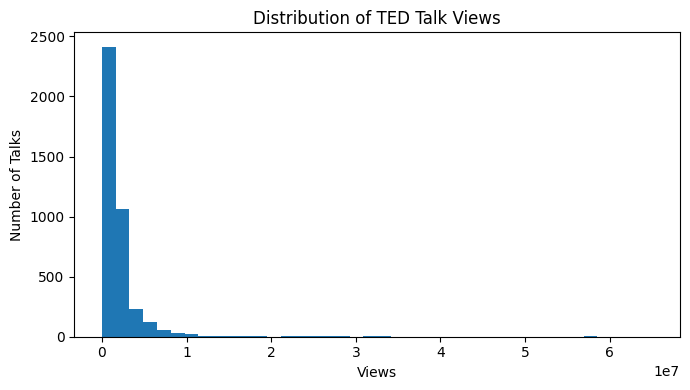

Potential view outliers: 393


,title,views
1,The best stats you've ever seen,14501685
4,Do schools kill creativity?,65051954
6,Letting go of God,4636596
13,The radical promise of the multi-touch interface,4796806
20,Nerdcore comedy,7049090
22,"Why we love, why we cheat",11430399
24,Why the universe seems so strange,4032164
26,"Choice, happiness and spaghetti sauce",8677098
27,The freakonomics of crack dealing,4140957
28,The surprising science of happiness,18645468


In [ ]:

# Plot the original dataset's view distribution and identify potential outliers
import pandas as pd
import matplotlib.pyplot as plt

views = pd.to_numeric(df['views'], errors='coerce')

plt.figure(figsize=(7, 4))
plt.hist(views.dropna(), bins=40)
plt.xlabel('Views')
plt.ylabel('Number of Talks')
plt.title('Distribution of TED Talk Views')
plt.tight_layout()
plt.show()

q1 = views.quantile(0.25)
q3 = views.quantile(0.75)
iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

view_outliers = df[
    (views < lower_limit) | (views > upper_limit)
]

print("Potential view outliers:", len(view_outliers))
display(view_outliers[['title', 'views']].head(10))


In [ ]:
# Analyse TED Talk duration statistics and data quality

duration = pd.to_numeric(df['duration'], errors='coerce')

print("Mean duration:", round(duration.mean(), 2), "seconds")
print("Median duration:", duration.median(), "seconds")
print("Minimum duration:", duration.min(), "seconds")
print("Maximum duration:", duration.max(), "seconds")
print("Missing durations:", duration.isna().sum())
print("Zero or negative durations:", (duration <= 0).sum())

Mean duration: 724.01 seconds
Median duration: 738.0 seconds
Minimum duration: 60 seconds
Maximum duration: 3922 seconds
Missing durations: 0
Zero or negative durations: 0


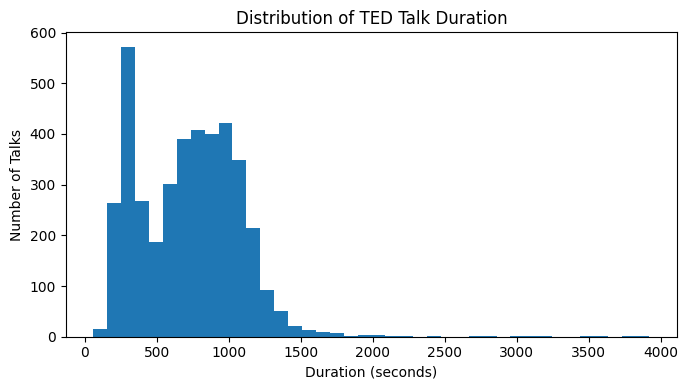

In [ ]:
# Plot the distribution of TED Talk durations

plt.figure(figsize=(7, 4))
plt.hist(duration.dropna(), bins=40)

plt.xlabel('Duration (seconds)')
plt.ylabel('Number of Talks')
plt.title('Distribution of TED Talk Duration')
plt.tight_layout()
plt.show()

In [ ]:
# Analyse recording and publication date ranges

for col in ['recorded_date', 'published_date']:
    df[col] = pd.to_datetime(df[col], errors='coerce')

    print(f"\n{col}")
    print("Earliest date:", df[col].min())
    print("Latest date:", df[col].max())
    print("Missing or invalid dates:", df[col].isna().sum())


recorded_date
Earliest date: 1984-02-02 00:00:00
Latest date: 2020-04-30 00:00:00
Missing or invalid dates: 1

published_date
Earliest date: 2006-06-27 00:00:00
Latest date: 2020-04-30 00:00:00
Missing or invalid dates: 0


,Number of Talks
Year,
2006,49
2007,119
2008,185
2009,215
2010,230
2011,255
2012,303
2013,242
2014,240


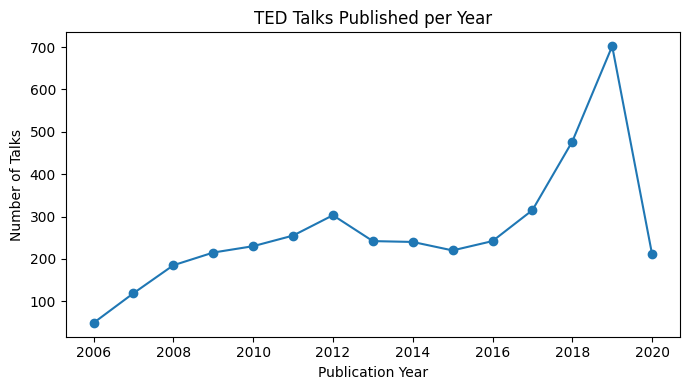

In [ ]:
# Count and visualise TED Talks published each year

df['published_year'] = df['published_date'].dt.year
yearly_talks = df['published_year'].value_counts().sort_index()

display(yearly_talks.rename_axis('Year').to_frame('Number of Talks'))

plt.figure(figsize=(7, 4))
plt.plot(yearly_talks.index, yearly_talks.values, marker='o')

plt.xlabel('Publication Year')
plt.ylabel('Number of Talks')
plt.title('TED Talks Published per Year')
plt.tight_layout()
plt.show()

In [ ]:
# Analyse native languages and available translations

print("Top 15 native languages:")
display(
    df['native_lang'].value_counts().head(15)
    .rename_axis('Language')
    .to_frame('Number of Talks')
)

def parse_languages(value):
    if pd.isna(value):
        return []
    try:
        result = ast.literal_eval(value) if isinstance(value, str) else value
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError):
        return []

available_languages = df['available_lang'].apply(parse_languages)

language_counter = Counter(
    str(language).strip().lower()
    for languages in available_languages
    for language in languages
    if str(language).strip()
)

print("\nTop 15 available languages:")
display(
    pd.DataFrame(
        language_counter.most_common(15),
        columns=['Language', 'Number of Talks']
    )
)

print("\nMissing native languages:", df['native_lang'].isna().sum())
print("Missing available languages:", df['available_lang'].isna().sum())
print("Talks with no parsed available languages:",
      (available_languages.apply(len) == 0).sum())

Top 15 native languages:


,Number of Talks
Language,
en,3957
es,27
fr,9
ja,3
hi,2
de,1
pt,1
ko,1
pt-br,1



Top 15 available languages:


,Language,Number of Talks
0,en,4005
1,es,3915
2,pt-br,3899
3,fr,3863
4,ar,3841
5,zh-tw,3818
6,zh-cn,3788
7,ko,3755
8,ru,3676
9,tr,3610



Missing native languages: 0
Missing available languages: 0
Talks with no parsed available languages: 0


,Number of Talks
Event,
TED-Ed,556
TED2017,96
TED2018,96
TED2019,91
TED2014,84
TED2009,81
TED2016,75
TED2015,75
TED2013,75


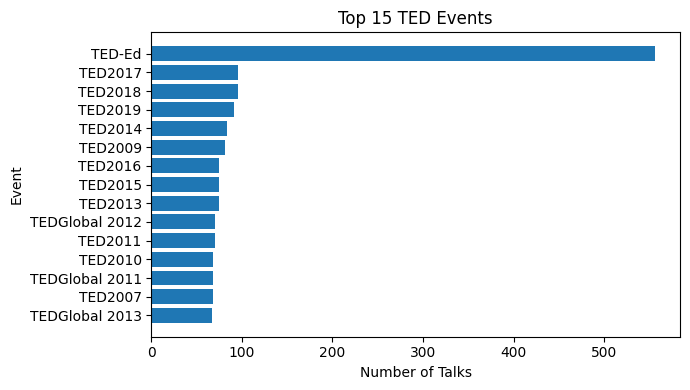

In [ ]:
# Analyse and visualise the most frequent TED events

event_counts = df['event'].value_counts().head(15)

display(event_counts.rename_axis('Event').to_frame('Number of Talks'))

plt.figure(figsize=(7, 4))
plt.barh(event_counts.index[::-1], event_counts.values[::-1])

plt.xlabel('Number of Talks')
plt.ylabel('Event')
plt.title('Top 15 TED Events')
plt.tight_layout()
plt.show()

,Occupation,Occurrences
0,author,158
1,writer,143
2,entrepreneur,105
3,artist,90
4,activist,83
5,journalist,82
6,educator,69
7,designer,67
8,inventor,61
9,neuroscientist,50


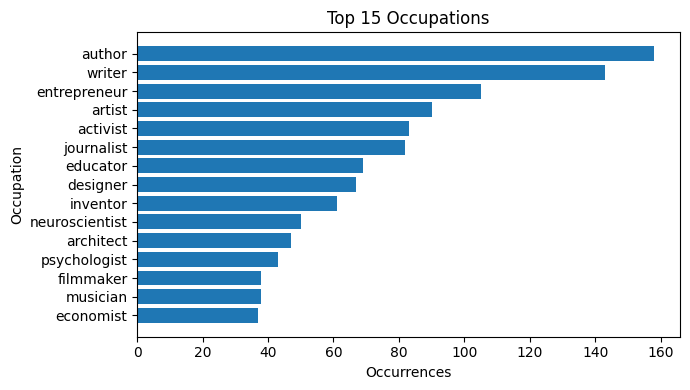

In [ ]:
# Count occupation labels from the occupations column

occupation_counter = Counter()

for value in df['occupations'].dropna():
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else value
    except (ValueError, SyntaxError):
        continue

    if isinstance(parsed, dict):
        for occupation in parsed.values():
            if isinstance(occupation, list):
                occupation_counter.update(
                    str(item).strip() for item in occupation
                    if str(item).strip()
                )
            elif isinstance(occupation, str) and occupation.strip():
                occupation_counter[occupation.strip()] += 1

    elif isinstance(parsed, list):
        occupation_counter.update(
            str(item).strip() for item in parsed
            if str(item).strip()
        )

top_occupations = pd.DataFrame(
    occupation_counter.most_common(15),
    columns=['Occupation', 'Occurrences']
)

display(top_occupations)

if not top_occupations.empty:
    plt.figure(figsize=(7, 4))
    plt.barh(
        top_occupations['Occupation'][::-1],
        top_occupations['Occurrences'][::-1]
    )

    plt.xlabel('Occurrences')
    plt.ylabel('Occupation')
    plt.title('Top 15 Occupations')
    plt.tight_layout()
    plt.show()

In [ ]:
# Analyse TED Talk comments and identify the most-commented talks

comments = pd.to_numeric(df['comments'], errors='coerce')

print("Mean comments:", round(comments.mean(), 2))
print("Median comments:", comments.median())
print("Minimum comments:", comments.min())
print("Maximum comments:", comments.max())
print("Missing comments:", comments.isna().sum())

top_commented = df.loc[
    comments.nlargest(10).index,
    ['title', 'speaker_1', 'comments', 'url']
]

display(top_commented)

Mean comments: 162.0
Median comments: 89.0
Minimum comments: 0.0
Maximum comments: 6449.0
Missing comments: 655


,title,speaker_1,comments,url
94,Militant atheism,Richard Dawkins,6449.0,https://www.ted.com/talks/richard_dawkins_mili...
4,Do schools kill creativity?,Sir Ken Robinson,4931.0,https://www.ted.com/talks/sir_ken_robinson_do_...
617,Science can answer moral questions,Sam Harris,3424.0,https://www.ted.com/talks/sam_harris_science_c...
1735,How do you explain consciousness?,David Chalmers,3006.0,https://www.ted.com/talks/david_chalmers_how_d...
197,My stroke of insight,Jill Bolte Taylor,2984.0,https://www.ted.com/talks/jill_bolte_taylor_my...
1296,Your body language may shape who you are,Amy Cuddy,2633.0,https://www.ted.com/talks/amy_cuddy_your_body_...
911,Taking imagination seriously,Janet Echelman,2529.0,https://www.ted.com/talks/janet_echelman_takin...
799,On reading the Koran,Lesley Hazleton,2463.0,https://www.ted.com/talks/lesley_hazleton_on_r...
631,The danger of science denial,Michael Specter,2366.0,https://www.ted.com/talks/michael_specter_the_...
796,The power of vulnerability,Brené Brown,2209.0,https://www.ted.com/talks/brene_brown_the_powe...


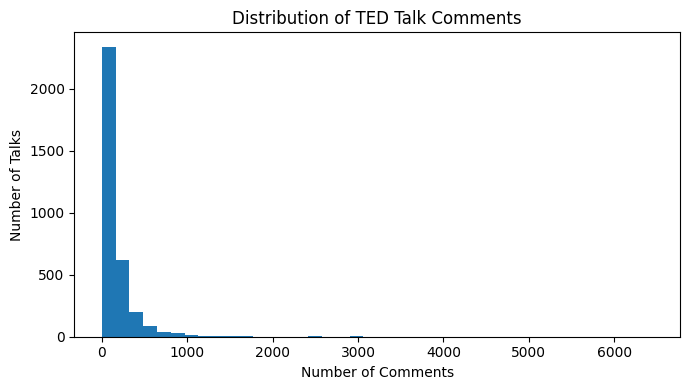

Potential comment outliers: 261


,title,comments
1,The best stats you've ever seen,628.0
4,Do schools kill creativity?,4931.0
6,Letting go of God,980.0
7,Let's teach religion -- all religion -- in sch...,919.0
8,A life of purpose,930.0
22,"Why we love, why we cheat",605.0
24,Why the universe seems so strange,533.0
28,The surprising science of happiness,1051.0
29,The paradox of choice,1065.0
31,A roadmap to end aging,624.0


In [ ]:
# Visualise comment distribution and identify potential outliers

plt.figure(figsize=(7, 4))
plt.hist(comments.dropna(), bins=40)

plt.xlabel('Number of Comments')
plt.ylabel('Number of Talks')
plt.title('Distribution of TED Talk Comments')
plt.tight_layout()
plt.show()

q1 = comments.quantile(0.25)
q3 = comments.quantile(0.75)
iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

comment_outliers = df[
    (comments < lower_limit) | (comments > upper_limit)
]

print("Potential comment outliers:", len(comment_outliers))

display(comment_outliers[['title', 'comments']].head(10))

In [ ]:
# Analyse related-talk relationships and check referenced talk IDs

def parse_dict(value):
    if pd.isna(value):
        return {}
    try:
        result = ast.literal_eval(value) if isinstance(value, str) else value
        return result if isinstance(result, dict) else {}
    except (ValueError, SyntaxError):
        return {}

related_talks = df['related_talks'].apply(parse_dict)

# Count related talks associated with each entry
related_counts = related_talks.apply(len)

print("Average related talks:", round(related_counts.mean(), 2))
print("Minimum related talks:", related_counts.min())
print("Maximum related talks:", related_counts.max())
print("Talks with no related-talk references:", (related_counts == 0).sum())

# Collect referenced talk IDs
referenced_ids = set()

for related in related_talks:
    for key in related.keys():
        try:
            referenced_ids.add(int(key))
        except (ValueError, TypeError):
            continue

# Compare referenced IDs with IDs in the dataset
dataset_ids = set(df['talk_id'].dropna().astype(int))
missing_related_ids = referenced_ids - dataset_ids

print("Unique referenced IDs:", len(referenced_ids))
print("Referenced IDs absent from dataset:", len(missing_related_ids))
print("Sample absent IDs:", sorted(missing_related_ids)[:20])

Average related talks: 5.97
Minimum related talks: 1
Maximum related talks: 6
Talks with no related-talk references: 0
Unique referenced IDs: 3822
Referenced IDs absent from dataset: 56
Sample absent IDs: [24, 96, 138, 169, 186, 265, 541, 581, 631, 720, 721, 722, 730, 745, 747, 756, 775, 784, 798, 816]


In [ ]:
# Clean the dataset while preserving the original DataFrame
clean_df = df.copy()

text_columns = [
    'title', 'speaker_1', 'all_speakers', 'occupations',
    'about_speakers', 'event', 'native_lang', 'available_lang',
    'topics', 'related_talks', 'url', 'description', 'transcript'
]

for col in text_columns:
    clean_df[col] = clean_df[col].apply(
        lambda x: re.sub(r'\s+', ' ', x).strip()
        if isinstance(x, str) else x
    )

for col in ['recorded_date', 'published_date']:
    clean_df[col] = pd.to_datetime(clean_df[col], errors='coerce')

for col in ['views', 'comments', 'duration']:
    clean_df[col] = pd.to_numeric(clean_df[col], errors='coerce')

rows_before = len(clean_df)
clean_df = clean_df.drop_duplicates()
clean_df = clean_df.drop_duplicates(subset='talk_id', keep='first')

print("Original rows:", rows_before)
print("Cleaned rows:", len(clean_df))
print("Rows removed:", rows_before - len(clean_df))
print("Duplicate talk IDs remaining:", clean_df['talk_id'].duplicated().sum())

Original rows: 4005
Cleaned rows: 4005
Rows removed: 0
Duplicate talk IDs remaining: 0


In [ ]:
# Handle missing values in all relevant columns
clean_df['occupations'] = clean_df['occupations'].fillna('Unknown')
clean_df['about_speakers'] = clean_df['about_speakers'].fillna('')
clean_df['all_speakers'] = clean_df['all_speakers'].fillna(clean_df['speaker_1'])

# Fill missing comments with the median and missing dates with the most frequent date
clean_df['comments'] = clean_df['comments'].fillna(clean_df['comments'].median())
clean_df['recorded_date'] = clean_df['recorded_date'].fillna(clean_df['recorded_date'].mode()[0])

# Display remaining missing values
print("Missing values after handling:")
print(clean_df.isnull().sum()[clean_df.isnull().sum() > 0])

Missing values after handling:
Series([], dtype: int64)


In [ ]:
# Convert each talk's topic list into a single text string
def topics_to_text(value):
    topics = parse_list(value)
    return ' '.join(str(topic).strip() for topic in topics)

clean_df['topics_text'] = clean_df['topics'].apply(topics_to_text)

display(clean_df[['title', 'topics', 'topics_text']].head())

,title,topics,topics_text
0,Averting the climate crisis,"['alternative energy', 'cars', 'climate change...",alternative energy cars climate change culture...
1,The best stats you've ever seen,"['Africa', 'Asia', 'Google', 'demo', 'economic...",Africa Asia Google demo economics global issue...
2,Simplicity sells,"['computers', 'entertainment', 'interface desi...",computers entertainment interface design media...
3,Greening the ghetto,"['MacArthur grant', 'activism', 'business', 'c...",MacArthur grant activism business cities envir...
4,Do schools kill creativity?,"['children', 'creativity', 'culture', 'dance',...",children creativity culture dance education pa...


In [ ]:
# Combine the main content fields for recommendation preparation
def safe_text(value):
    if pd.isna(value):
        return ''
    return re.sub(r'\s+', ' ', str(value)).strip()

clean_df['combined_text'] = (
    clean_df['title'].apply(safe_text) + ' ' +
    clean_df['topics_text'].apply(safe_text) + ' ' +
    clean_df['description'].apply(safe_text) + ' ' +
    clean_df['transcript'].apply(safe_text)
).str.strip()

print("Empty combined-text entries:",
      (clean_df['combined_text'] == '').sum())

display(clean_df[['title', 'topics_text', 'combined_text']].head(3))

Empty combined-text entries: 0


,title,topics_text,combined_text
0,Averting the climate crisis,alternative energy cars climate change culture...,Averting the climate crisis alternative energy...
1,The best stats you've ever seen,Africa Asia Google demo economics global issue...,The best stats you've ever seen Africa Asia Go...
2,Simplicity sells,computers entertainment interface design media...,Simplicity sells computers entertainment inter...


In [ ]:
# Save the cleaned dataset to Google Drive
OUTPUT_PATH = os.path.join(PROJECT_DIR, 'ted_talks_cleaned.csv')

clean_df.to_csv(OUTPUT_PATH, index=False)

print("Cleaned dataset saved successfully!")
print("File path:", OUTPUT_PATH)
print("Final dataset shape:", clean_df.shape)

Cleaned dataset saved successfully!
File path: /content/drive/MyDrive/TED_Talk_Recommendation/ted_talks_cleaned.csv
Final dataset shape: (4005, 23)


In [ ]:
# Verify the exported CSV and its key columns
verified_df = pd.read_csv(OUTPUT_PATH)

print("Saved file exists:", os.path.exists(OUTPUT_PATH))
print("Verified dataset shape:", verified_df.shape)
print("Required columns present:",
      all(col in verified_df.columns for col in
          ['title', 'topics_text', 'description', 'transcript', 'combined_text']))

display(verified_df[['title', 'topics_text', 'combined_text']].head(3))

Saved file exists: True
Verified dataset shape: (4005, 23)
Required columns present: True


,title,topics_text,combined_text
0,Averting the climate crisis,alternative energy cars climate change culture...,Averting the climate crisis alternative energy...
1,The best stats you've ever seen,Africa Asia Google demo economics global issue...,The best stats you've ever seen Africa Asia Go...
2,Simplicity sells,computers entertainment interface design media...,Simplicity sells computers entertainment inter...


In [ ]:
# Summarise EDA findings and confirm recommendation readiness

print("TED TALK RECOMMENDATION SYSTEM — FINAL EDA SUMMARY")
print("=" * 55)

print("\n1. DATASET")
print("Original shape:", df.shape)
print("Cleaned shape:", clean_df.shape)
print("Duplicate rows removed:", rows_before - len(clean_df))

print("\n2. DATA QUALITY")
print("Missing comments:", clean_df['comments'].isna().sum())
print("Missing occupations:", clean_df['occupations'].isna().sum())
print("Missing speaker biographies:", clean_df['about_speakers'].isna().sum())
print("Missing recording dates:", clean_df['recorded_date'].isna().sum())
print("Empty combined-text entries:",
      (clean_df['combined_text'].str.strip() == '').sum())

print("\n3. TOPICS")
display(top_topics.head(5))

print("\n4. SPEAKERS")
display(speaker_counts.head(5).rename_axis('Speaker')
        .to_frame('Number of Talks'))

print("\n5. MOST-VIEWED TALKS")
display(top_viewed[['title', 'speaker_1', 'views']].head(5))

print("\n6. RECOMMENDATION READINESS")
print("Unique talk IDs:", clean_df['talk_id'].is_unique)
print("Combined text column available:",
      'combined_text' in clean_df.columns)
print("Recommended approach: Content-based filtering")
print("Model training: Not performed")
print("Frontend development: Not performed")
print("Cleaned CSV:", OUTPUT_PATH)

TED TALK RECOMMENDATION SYSTEM — FINAL EDA SUMMARY

1. DATASET
Original shape: (4005, 21)
Cleaned shape: (4005, 23)
Duplicate rows removed: 0

2. DATA QUALITY
Missing comments: 0
Missing occupations: 0
Missing speaker biographies: 0
Missing recording dates: 0
Empty combined-text entries: 0

3. TOPICS


,Topic,Number of Talks
0,science,993
1,technology,979
2,culture,680
3,TEDx,581
4,global issues,574



4. SPEAKERS


,Number of Talks
Speaker,
Alex Gendler,34
Iseult Gillespie,19
Emma Bryce,12
Daniel Finkel,11
Alex Rosenthal,10



5. MOST-VIEWED TALKS


,title,speaker_1,views
4,Do schools kill creativity?,Sir Ken Robinson,65051954
1296,Your body language may shape who you are,Amy Cuddy,57074270
2062,This is what happens when you reply to spam email,James Veitch,56932551
646,How great leaders inspire action,Simon Sinek,49730580
796,The power of vulnerability,Brené Brown,47544833



6. RECOMMENDATION READINESS
Unique talk IDs: True
Combined text column available: True
Recommended approach: Content-based filtering
Model training: Not performed
Frontend development: Not performed
Cleaned CSV: /content/drive/MyDrive/TED_Talk_Recommendation/ted_talks_cleaned.csv
